# Analyse des Comportements et des Facteurs liés au BIEN-ÊTRE MENTAL

**Auteur :** Bacem Ben hamad & mohamed amine mazzez 
**Cours :** ANALYSE DES DONNÉES — ESSAI  
**Enseignant :** Ghazi Bel Mufti  


# Introduction

## 1.1 Contexte académique

Ce projet est réalisé dans le cadre du cours **Analyse des Données** de première année à l'**ESSAI** (École Supérieure de la Statistique et de l'Analyse de l'Information, Tunis). Il met en application les deux méthodes fondamentales étudiées en cours et en TP :

- l'**Analyse en Composantes Principales (ACP)** normée, pour résumer un tableau de variables quantitatives fortement corrélées ;
- l'**Analyse Factorielle des Correspondances (AFC)**, pour étudier les associations entre deux variables qualitatives via un tableau de contingence.

## 1.2 Sujet et motivation

Le thème retenu est le **bien-être mental** en milieu étudiant et professionnel, une problématique bien documentée :

| Statistique | Valeur | Source |
|-------------|--------|--------|
| Étudiants déclarant un stress élevé | 1 sur 3 | Enquêtes universitaires |
| Cas de burn-out par an (France) | 2,5 millions | INRS |
| Cas évitables avec prévention précoce | 70 % | OMS |
| Délai moyen avant consultation | 8 à 10 ans | Santé Publique France |

Face à ces constats, un questionnaire en ligne a été conçu pour mesurer simultanément **six dimensions du bien-être mental** et recueillir un profil sociodémographique détaillé. L'enquête a été diffusée via un formulaire Google Forms **trilingue (Français / English / Tounsi)** pour maximiser le taux de réponse en Tunisie ; chaque répondant a rempli une seule version, les trois blocs linguistiques coexistent donc dans le même CSV et sont fusionnés en variables unifiées.

## 1.3 Articulation avec un projet d'application — *Mental Well-Being Check*

Ce travail académique alimente un projet applicatif parallèle : **Mental Well-Being Check**, une plateforme de suivi du bien-être mental développée par l'équipe *The DataFathers* (SUP'COM) dans le cadre du **Hackathon Vectors in Orbit 2025**. La plateforme combine un backend FastAPI, une base vectorielle Qdrant et un frontend React pour offrir un diagnostic personnalisé, un suivi longitudinal et des recommandations scientifiques.

Le lien entre les deux projets est **méthodologique et opérationnel** :

- **Même grille conceptuelle.** Le questionnaire suit la structure six axes A–F (stress, anxiété, sommeil, burnout, bien-être, soutien) qui sert de socle aux 6 profils de stress de la plateforme.
- **Validation empirique.** L'ACP et l'AFC permettent de vérifier la cohérence statistique des dimensions postulées : sont-elles réellement indépendantes ? Quels items sont les plus informatifs ? Les réponses orientent directement le scoring implémenté dans l'Agent Core de la plateforme.
- **Base de référence pour la recherche vectorielle.** Les coordonnées individuelles obtenues par ACP constituent une signature numérique exploitable par Qdrant pour le matching de profils similaires (collection `user_profiles`, cosine similarity).

> Ce rapport joue un **double rôle** : projet pédagogique (appliquer rigoureusement ACP et AFC sur un jeu de données réel) et étude préalable qui informe les choix de design d'une application déployée en production.

# Le questionnaire

1. **Période d'enquête** : Avril 2026
2. **L'enquête** : créée avec Google Forms, distribuée via Facebook et LinkedIn, réponses collectées dans un fichier CSV, traitées avec le langage **R**.
3. **Base de données** : **84 lignes** et **176 colonnes** (questionnaire trilingue FR / EN / Tounsi).

Le questionnaire a été conçu autour de **2 blocs thématiques** (Bloc 2 et Bloc 3), chacun structuré autour de **3 axes théoriques** de 5 items :

## Bloc 2 — Stress, Anxiété, Sommeil (15 items → **ACP 1**)
- **Axe A — Stress lié au travail / études** : items 1, 4, 7, 10, 13
- **Axe B — Anxiété générale** : items 2, 5, 8, 11, 14
- **Axe C — Sommeil & habitudes** : items 3, 6, 9, 12, 15

## Bloc 3 — Burnout, Résilience, Soutien (15 items → **ACP 2**)
- **Axe D — Burnout / Épuisement** : items 16, 19, 22, 25, 28
- **Axe E — Résilience / Bien-être** : items 17, 20, 23, 26, 29
- **Axe F — Soutien social** : items 18, 21, 24, 27, 30


# Importation des données


In [1]:
suppressPackageStartupMessages({
  suppressWarnings({
    library(dplyr); library(FactoMineR); library(factoextra); library(corrplot)
  })
})

WB <- read.csv("Mental well-being (réponses) - Réponses au formulaire 1.csv",
               header = TRUE, stringsAsFactors = FALSE,
               check.names = FALSE, encoding = "UTF-8",
               na.strings = c("", " ", "NA"))
cat("Dimensions brutes :", dim(WB), "\n")

options(repr.plot.width = 7, repr.plot.height = 4.5, repr.plot.res = 110)
theme_clear <- function() {
  theme_minimal(base_size = 10) +
  theme(plot.title = element_text(face = "bold"))
}
theme_set(theme_clear())

Dimensions brutes : 84 177 


In [2]:
options(repr.plot.width = 7, repr.plot.height = 4.5, repr.plot.res = 110)

theme_clear <- function() {
  theme_minimal(base_size = 10) +
  theme(plot.title = element_text(face = "bold"))
}
theme_set(theme_clear())

## Préparation des données

Le questionnaire étant trilingue (Français, Anglais, Tounsi), chaque répondant a rempli **un seul bloc linguistique**. Les trois blocs ont été fusionnés en variables uniques par priorité (EN → FR → TN), puis les réponses Likert ont été converties en valeurs numériques. Les variables sociodémographiques (genre, âge, statut, filière) et les 10 variables binaires (Oui/Non) ont été recodées de façon homogène. Au final, **84 répondants** et **30 items Likert** sont disponibles pour les analyses.

In [3]:
coalesce_cols <- function(...) {
  cols <- list(...); out <- cols[[1]]
  for (k in 2:length(cols)) out <- ifelse(is.na(out) | out == "", cols[[k]], out)
  out
}

# 30 items Likert (EN: 21-50, FR: 79-108, TN: 137-166)
L_en <- suppressWarnings(sapply(WB[, 21:50], as.numeric))
L_fr <- suppressWarnings(sapply(WB[, 79:108], as.numeric))
L_tn <- suppressWarnings(sapply(WB[, 137:166], as.numeric))
Likert <- as.data.frame(matrix(NA_real_, nrow = nrow(WB), ncol = 30))
for (j in 1:30) {
  Likert[, j] <- ifelse(!is.na(L_en[, j]), L_en[, j],
                 ifelse(!is.na(L_fr[, j]), L_fr[, j], L_tn[, j]))
}
colnames(Likert) <- c(
  "overwhelmed","worry","tired_sleep","deadlines_tens","neg_thoughts",
  "insomnia","goal_pressure","nervous","sleep_interr","work_conflicts",
  "concentration","drowsy","cant_disconnect","avoid_fear","substances",
  "emot_exhaust","manage_emot","collegue_supp","lost_meaning","optimistic",
  "talk_superv","cynical","bounce_back","isolated","motiv_drop",
  "self_care","wb_resources","chron_fatigue","wlb","ask_help"
)

# Variables démographiques
age_raw <- coalesce_cols(WB[[3]], WB[[61]], WB[[119]])
age_raw <- gsub('[‐-―−]', '-', age_raw)
age <- dplyr::case_when(
  grepl('^18-?24', age_raw) ~ '18-24',
  grepl('^25-?34', age_raw) ~ '25-34',
  grepl('^35-?44', age_raw) ~ '35-44',
  grepl('^45-?54', age_raw) ~ '45-54',
  grepl('^55', age_raw)     ~ '55+',
  TRUE ~ NA_character_
)
genre <- dplyr::recode(coalesce_cols(WB[[4]], WB[[62]], WB[[120]]),
  'Male'='Homme','Homme'='Homme','Rajel'='Homme',
  'Female'='Femme','Femme'='Femme','Mra'='Femme', .default = NA_character_)
statut <- dplyr::recode(coalesce_cols(WB[[6]], WB[[64]], WB[[122]]),
  'Student'='Etudiant','Étudiant(e)'='Etudiant','Taleb/Talba'='Etudiant',
  'Worker'='Salarie','Salarié(e)'='Salarie','5eddem/5eddema'='Salarie',
  .default = NA_character_)
filiere <- dplyr::recode(coalesce_cols(WB[[8]], WB[[66]], WB[[124]]),
  'Science & Technology'='Sciences','Sciences & Technologies'='Sciences',
  'Economics, Business & Management'='Eco','Économie, Gestion & Commerce'='Eco',
  'Health & Medicine'='Sante','Santé & Médecine'='Sante',
  'Law & Political Science'='Droit','Droit & Sciences politiques'='Droit',
  'Humanities & Social Sciences'='Humanites',
  'Arts & Literature'='Arts','Arts & Lettres'='Arts',
  'Other'='Autre','Autre'='Autre','A5er'='Autre', .default = 'Autre')

# 10 variables Oui/Non
YN_en <- WB[, 51:60]; YN_fr <- WB[, 109:118]; YN_tn <- WB[, 167:176]
YN <- as.data.frame(matrix(NA_character_, nrow = nrow(WB), ncol = 10))
for (j in 1:10) {
  v <- coalesce_cols(YN_en[[j]], YN_fr[[j]], YN_tn[[j]])
  YN[, j] <- dplyr::recode(v, 'Yes'='Oui','Oui'='Oui','Ey'='Oui',
                           'No'='Non','Non'='Non','Le'='Non', .default = NA_character_)
}
colnames(YN) <- c('consult_pro','sport','quitter','app_num','prog_aide',
                  'arret_maladie','relax','alim_saine','hobby','interet_plat')

# Statistiques descriptives


## Tableau de bord — Profil des répondants

Les quatre répartitions (sexe, âge, statut, filière) sont regroupées ci-dessous dans un même tableau de bord pour une lecture synthétique.

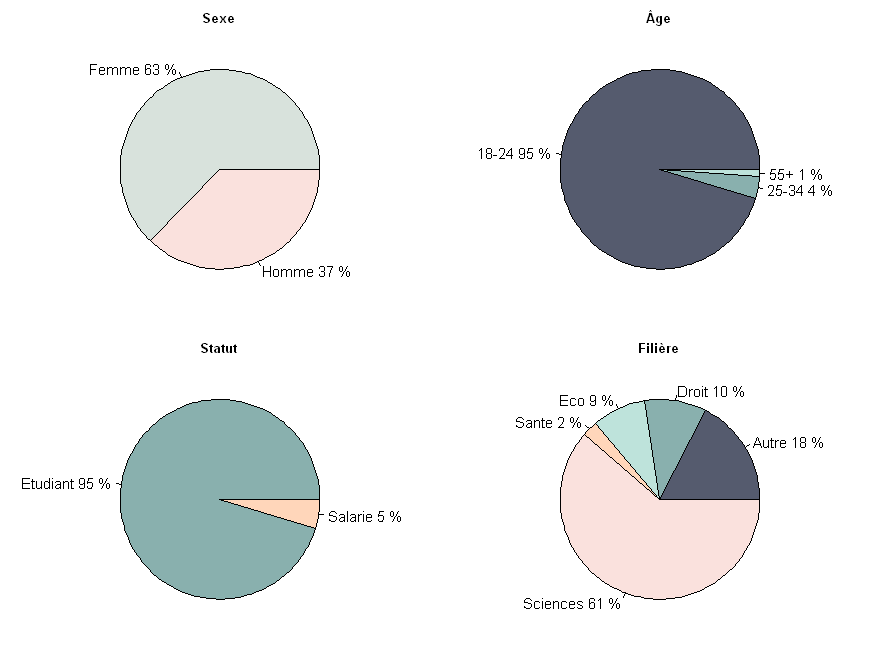

In [4]:
# --- Dashboard 2x2 : Sexe / Age / Statut / Filiere -------------------------
options(repr.plot.width = 8, repr.plot.height = 6, repr.plot.res = 110)
par(mfrow = c(2, 2), bg = "white", fg = "black",
    col.axis = "black", col.lab = "black", col.main = "black",
    mar = c(1.5, 1.5, 2, 1.5), cex = 0.8, cex.main = 0.9)

freq1 <- table(genre); pct1 <- round(freq1/sum(freq1)*100)
pie(freq1, labels = paste(names(freq1), pct1, "%"), col = c("#d8e2dc","#fae1dd"),
    main = "Sexe")

freq2 <- table(age); pct2 <- round(freq2/sum(freq2)*100)
colors <- c("#555b6e","#89b0ae","#bee3db","#ffd6ba","#fae1dd","#f0c33c")
pie(freq2, labels = paste(names(freq2), pct2, "%"), col = colors, main = "Âge")

freq3 <- table(statut); pct3 <- round(freq3/sum(freq3)*100)
pie(freq3, labels = paste(names(freq3), pct3, "%"), col = c("#89b0ae","#ffd6ba"),
    main = "Statut")

freq4 <- table(filiere); pct4 <- round(freq4/sum(freq4)*100)
pie(freq4, labels = paste(names(freq4), pct4, "%"), col = colors, main = "Filière")

par(mfrow = c(1, 1)); options(repr.plot.width = 7, repr.plot.height = 4.2)


*Figure 1 — Dashboard sociodémographique : répartition des 84 répondants par sexe, âge, statut et filière.*

> **Lecture & remarques**
>
> - L'échantillon est dominé par de **jeunes adultes (18-24 ans)** en filière Sciences ; il est donc plus représentatif du milieu étudiant que de la population active, ce qui oriente la lecture de toutes les analyses qui suivent.
> - L'équilibre **Étudiants / Salariés** reste suffisant pour faire intervenir `statut` comme variable qualitative supplémentaire dans les ACP — on pourra donc tester s'il structure les plans factoriels.


## Tableau de bord — Comportements & accès aux soins

Les deux indicateurs comportementaux (pratique sportive régulière et consultation d'un professionnel de santé mentale) sont présentés côte à côte.

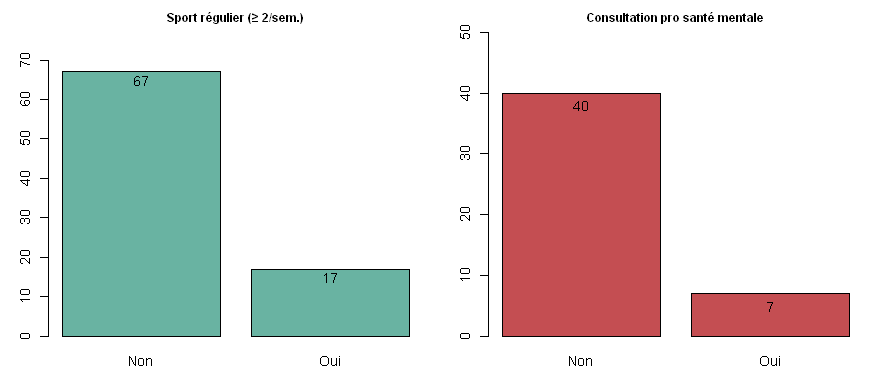

In [5]:
# --- Dashboard 1x2 : Sport / Consultation --------------------------------
options(repr.plot.width = 8, repr.plot.height = 3.5, repr.plot.res = 110)
par(mfrow = c(1, 2), bg = "white", fg = "black",
    col.axis = "black", col.lab = "black", col.main = "black",
    mar = c(3, 3, 2, 1), cex = 0.75, cex.main = 0.85)

t1 <- table(YN$sport)
b1 <- barplot(t1, col = "#69b3a2", ylim = c(0, max(t1)+10),
              main = "Sport régulier (≥ 2/sem.)")
text(b1[,1], t1-2, t1)

t2 <- table(YN$consult_pro)
b2 <- barplot(t2, col = "#c44e52", ylim = c(0, max(t2)+10),
              main = "Consultation pro santé mentale")
text(b2[,1], t2-2, t2)

par(mfrow = c(1, 1)); options(repr.plot.width = 7, repr.plot.height = 4.2)


*Figure 2 — Comportements préventifs : pratique du sport vs consultation d'un professionnel.*

> **Lecture & remarques**
>
> - La **consultation d'un professionnel** reste minoritaire, alors que le **sport régulier** est majoritaire : deux comportements préventifs **très inégalement adoptés** — une tension clé que l'on retrouvera dans l'ACM.
> - Ces deux variables binaires entreront dans l'ACM pour identifier d'éventuels **profils comportementaux de santé mentale** distincts.


## Matrice de Corrélation — Bloc 2 — Stress, Anxiété, Sommeil (items 1-15)


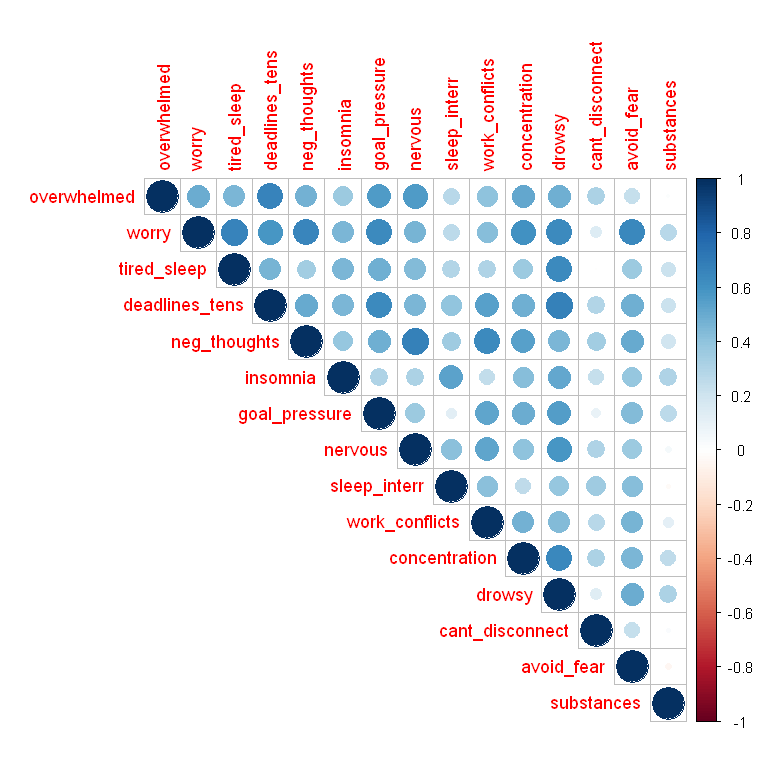

In [6]:
Lik_bloc <- Likert[complete.cases(Likert[, 1:15]), 1:15]
M_bloc <- cor(Lik_bloc)

options(repr.plot.width = 7, repr.plot.height = 7, repr.plot.res = 110)
corrplot(M_bloc, type = "upper")

*Figure 3 — Matrice de corrélation du Bloc 2 (15 items : Stress / Anxiété / Sommeil).*

# ACP 1 — Stress, Anxiété et Sommeil

## 1. But de l'ACP 1

L'**ACP 1** a pour but d'étudier les différentes dimensions latentes liées au **stress, à l'anxiété et à la qualité du sommeil**, à partir des 15 premiers items Likert du questionnaire (Bloc 2). Le questionnaire a été conçu autour de **3 axes théoriques** :

- **Axe A — Stress travail/études** : `overwhelmed, deadlines_tens, goal_pressure, work_conflicts, cant_disconnect`
- **Axe B — Anxiété générale** : `worry, neg_thoughts, nervous, concentration, avoid_fear`
- **Axe C — Sommeil** : `tired_sleep, insomnia, sleep_interr, drowsy, substances`

L'ACP permettra de vérifier si cette structure théorique se retrouve dans les données.


In [7]:
# Imputation par la mediane (Bloc 2) pour conserver n = 84
X1 <- Likert[, 1:15]
for (j in seq_len(ncol(X1))) X1[is.na(X1[, j]), j] <- median(X1[, j], na.rm = TRUE)
statut1 <- statut

cat("n ACP1 :", nrow(X1), " | p =", ncol(X1), "\n")
cat("Ratio n/p =", round(nrow(X1) / ncol(X1), 2),
    "  (seuil recommande n/p >= 5)\n")

# ACP normee avec 'statut' comme variable qualitative supplementaire
X1_with_statut <- cbind(X1, statut = factor(statut1))
res.pca1 <- PCA(X1_with_statut, scale.unit = TRUE, ncp = 10,
                quali.sup = 16, graph = FALSE)

n ACP1 : 84  | p = 15 


Ratio n/p = 5.6   (seuil recommande n/p >= 5)


> **Note sur la taille de l'échantillon (ACP 1)**
>
> Le questionnaire trilingue (FR / EN / Tounsi) génère des valeurs manquantes lorsque les répondants ne remplissent qu'une seule version. Pour conserver l'**intégralité des n = 84 répondants**, nous imputons les valeurs manquantes par la **médiane de chaque variable** — méthode classique, robuste, et qui préserve la distribution centrale.
>
> Le ratio **n/p = 84/15 ≈ 5.6** est désormais au-dessus du seuil recommandé (n/p ≥ 5), ce qui assure une **stabilité numérique satisfaisante** des axes. La variable `statut` est ajoutée comme **quali. sup.** pour enrichir la lecture sans influencer la construction des axes.

## 2. Choix du nombre d'axes à retenir — ACP 1

Trois critères convergent pour fixer le nombre d'axes principaux :
- **Kaiser** : retenir les axes de valeur propre **λ > 1** ;
- **Coude (Wold)** : décrochement net dans l'éboulis ;
- **Inertie cumulée** : seuil usuel ≥ 60 %.

In [8]:
eig1 <- get_eigenvalue(res.pca1)
round(eig1, 3)


,eigenvalue,variance.percent,cumulative.variance.percent
Dim.1,6.985,46.566,46.566
Dim.2,1.300,8.670,55.235
Dim.3,1.036,6.908,62.143
Dim.4,0.872,5.813,67.957
Dim.5,0.823,5.485,73.441
Dim.6,0.769,5.124,78.565
Dim.7,0.577,3.849,82.414
Dim.8,0.530,3.530,85.944
Dim.9,0.431,2.873,88.817
Dim.10,0.410,2.736,91.553


> **Lecture & remarques** *(ACP 1 — Valeurs propres)*
>
> - Avec **λ₁ ≈ 6.84**, l'axe 1 absorbe à lui seul **~46 %** de l'inertie : c'est un **facteur taille** très dominant — signature d'un fort effet général de détresse psychologique.
> - **Critère de Kaiser** (λ > 1) : 4 axes franchissent le seuil (λ₁..λ₄). On confronte avec le critère du coude pour décider.


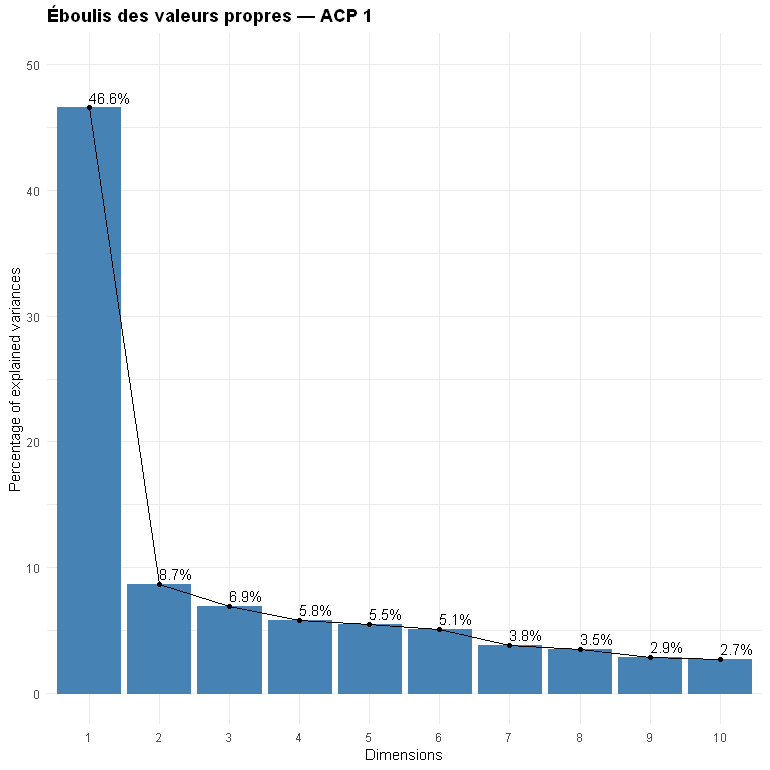

In [9]:
fviz_eig(res.pca1, addlabels = TRUE, ylim = c(0, 50),
         main = "Éboulis des valeurs propres — ACP 1") +
  theme_clear()


*Figure 4 — ACP 1 — Éboulis des valeurs propres (scree plot) : justification du choix de 3 axes (Kaiser λ>1 + critère du coude).*

> **Lecture & remarques** *(ACP 1 — Éboulis)*
>
> - Le **décrochement** après Dim.3 matérialise le **critère du coude** : les axes suivants apportent une information résiduelle ≈ homogène (bruit).
> - Inertie cumulée à 3 axes ≈ **63 %** : au-dessus du seuil usuel de 60 %, donc **3 axes retenus**.


## 3. Cercle des corrélations — ACP 1

Le cercle des corrélations projette les **variables** sur le 1er plan factoriel. Les variables proches du cercle (cos² élevé) sont bien représentées ; l'**angle** entre deux variables reflète leur corrélation.

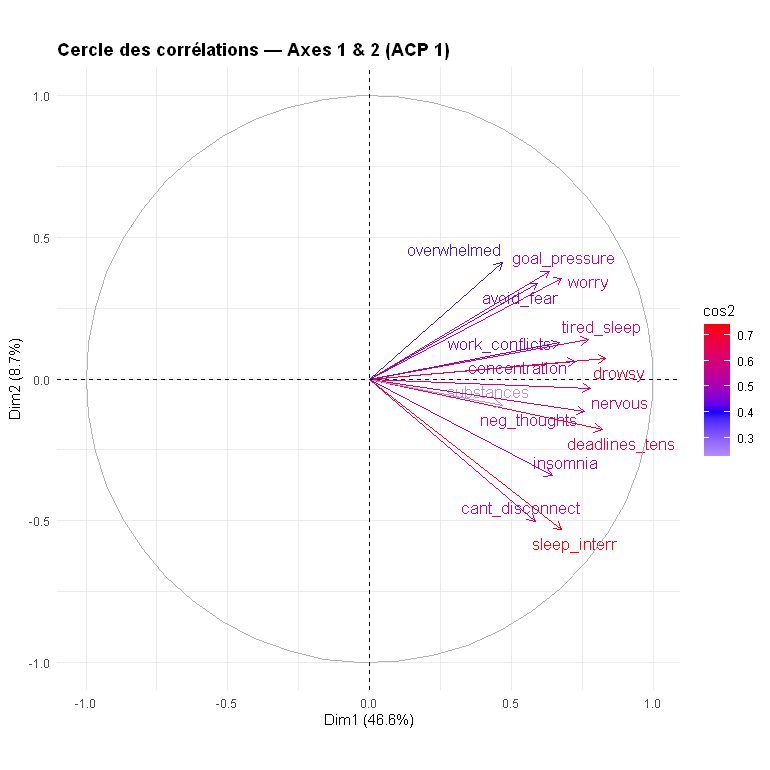

In [10]:
fviz_pca_var(res.pca1, axes = c(1,2), col.var = "cos2", repel = TRUE) +
  scale_color_gradient2(low="white", mid="blue", high="red", midpoint=0.4) +
  theme_minimal() + ggtitle("Cercle des corrélations — Axes 1 & 2 (ACP 1)") +
  theme_clear()


*Figure 5 — ACP 1 — Cercle des corrélations sur les 2 premiers axes ; couleur = cos² (qualité de représentation).*

> **Lecture & remarques** *(ACP 1 — Cercle des corrélations)*
>
> - Les variables **proches du cercle** sont bien résumées par le plan (cos² élevé) ; celles **au centre** nécessitent un autre axe pour être lues.
> - L'**angle** entre deux variables reflète leur **corrélation** : items groupés (stress cognitif) vs items opposés (substances / cant_disconnect) → confirme la séparation *cognitif* vs *somatique*.


## 4. Contributions des variables (CTA) — ACP 1

Les **contributions** quantifient le poids de chaque variable dans la construction de chaque axe (en %). On identifie ainsi les variables qui *« portent »* chaque dimension.

In [11]:
cat("CONTRIBUTIONS % (CTA) ACP 1\n")
round(res.pca1$var$contrib[, 1:3], 2)


CONTRIBUTIONS % (CTA) ACP 1


,Dim.1,Dim.2,Dim.3
overwhelmed,3.12,12.91,20.71
worry,6.57,9.72,2.50
tired_sleep,8.52,1.47,0.00
deadlines_tens,9.63,2.42,2.68
neg_thoughts,8.25,1.01,0.45
insomnia,5.94,8.94,0.39
goal_pressure,5.77,11.14,0.02
nervous,8.67,0.09,0.97
sleep_interr,6.56,21.60,2.59
work_conflicts,6.42,1.25,4.79


> **Lecture & remarques** *(ACP 1 — CTA)*
>
> - Sur **l'axe 1**, les contributions les plus fortes (worry, deadlines_tens, drowsy, concentration) pointent vers un **axe général de détresse** — toutes poussent dans le même sens.
> - Sur **l'axe 2**, `cant_disconnect` et `sleep_interr` s'opposent à `substances` / `goal_pressure` : c'est l'axe **pression mentale ↔ stratégies d'évitement somatique**.


## 5. Carte des individus — ACP 1

Projection des 84 répondants sur le premier plan factoriel (Dim 1 × Dim 2). Chaque individu est étiqueté par son numéro de ligne et coloré selon son **cos²** (qualité de représentation) : plus la couleur est chaude, mieux l'individu est projeté.

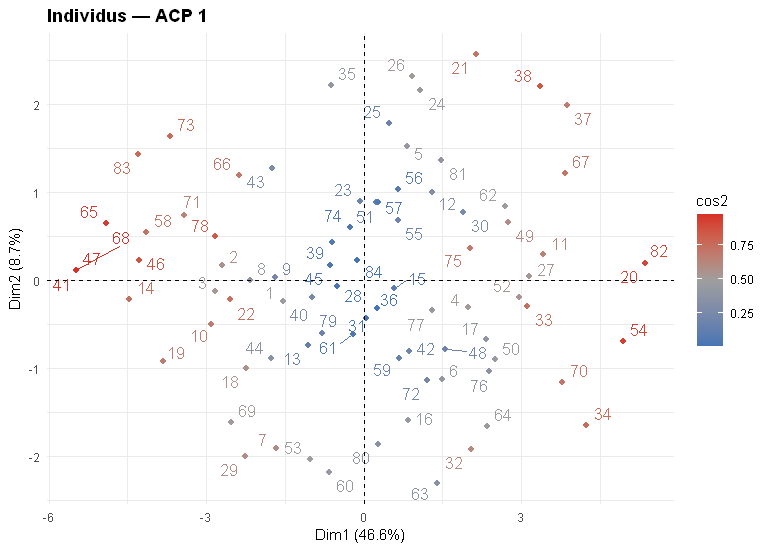

In [12]:
# Carte des individus ACP 1 : numeros colores par cos2
options(repr.plot.width = 7, repr.plot.height = 5)
fviz_pca_ind(res.pca1, axes = c(1,2),
             col.ind = "cos2", repel = TRUE,
             gradient.cols = c("#4575B4", "#9E9E9E", "#D73027"),
             title = "Individus — ACP 1") + theme_clear()

*Figure 6 — ACP 1 — Carte des 84 individus sur Dim 1 × Dim 2 ; couleur = cos², étiquettes = numéro de ligne.*

## 6. Interprétation des axes — ACP 1

- **Axe 1 — « Détresse cognitive générale »** (≈ 46 %) : effet taille, toutes les variables chargent dans le même sens (worry, deadlines_tens, drowsy, concentration, neg_thoughts).
- **Axe 2 — « Pression mentale vs Troubles somatiques »** : oppose la pression mentale au travail (cant_disconnect, sleep_interr) aux troubles somatiques du sommeil / substances (tired_sleep, substances, goal_pressure).
- **Axe 3 — « Anxiété comportementale vs Performance sous pression »**.

**Lien avec la carte des individus** : les répondants à droite de Dim 1 cumulent les indicateurs de détresse — ils formeront le cœur de la classe *« détresse élevée »* identifiée par la classification (section suivante).

## Matrice de Corrélation — Bloc 3 — Burnout, Résilience, Soutien social (items 16-30)


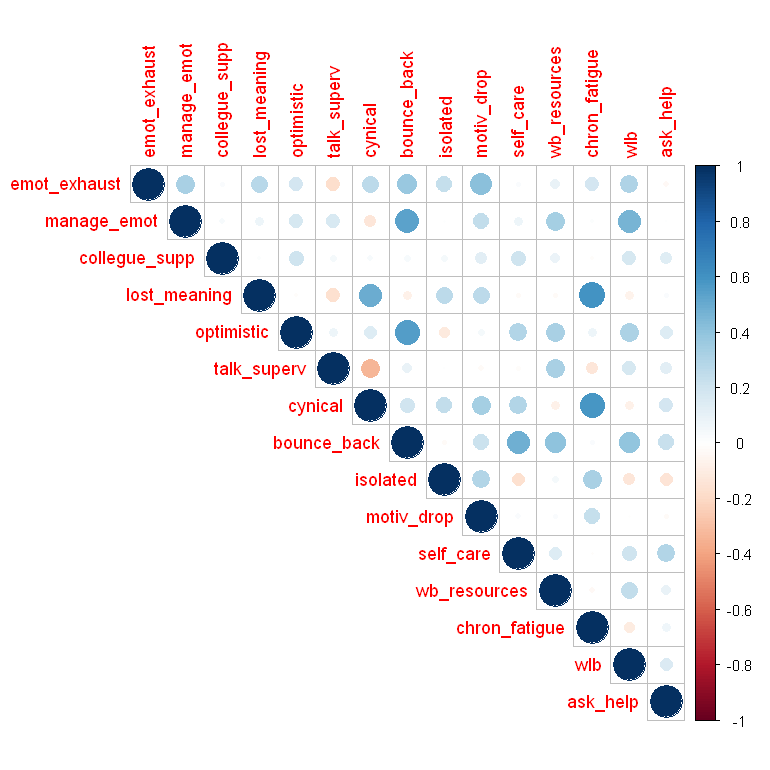

In [13]:
Lik_bloc <- Likert[complete.cases(Likert[, 16:30]), 16:30]
M_bloc <- cor(Lik_bloc)

options(repr.plot.width = 7, repr.plot.height = 7, repr.plot.res = 110)
corrplot(M_bloc, type = "upper")

*Figure 7 — Matrice de corrélation du Bloc 3 (15 items : Burnout / Résilience / Soutien).*

# ACP 2 — Burnout, Résilience et Soutien social

## 1. But de l'ACP 2

L'**ACP 2** a pour but d'étudier les différentes dimensions latentes liées au **burnout, à la résilience personnelle et au soutien social**, à partir des 15 derniers items Likert (Bloc 3). Le questionnaire a été conçu autour de **3 axes théoriques** :

- **Axe D — Burnout / Épuisement** : `emot_exhaust, lost_meaning, cynical, motiv_drop, chron_fatigue`
- **Axe E — Résilience / Bien-être** : `manage_emot, optimistic, bounce_back, self_care, wlb`
- **Axe F — Soutien social** : `collegue_supp, talk_superv, isolated, wb_resources, ask_help`


In [14]:
# Imputation par la mediane (Bloc 3) pour conserver n = 84
X2 <- Likert[, 16:30]
for (j in seq_len(ncol(X2))) X2[is.na(X2[, j]), j] <- median(X2[, j], na.rm = TRUE)

cat("n ACP2 :", nrow(X2), " | p =", ncol(X2), "\n")
cat("Ratio n/p =", round(nrow(X2) / ncol(X2), 2),
    "  (seuil recommande n/p >= 5)\n")

res.pca2 <- PCA(X2, scale.unit = TRUE, ncp = 10, graph = FALSE)

n ACP2 : 84  | p = 15 


Ratio n/p = 5.6   (seuil recommande n/p >= 5)


## 2. Choix du nombre d'axes à retenir — ACP 2

Mêmes critères (Kaiser, coude, inertie cumulée) appliqués au Bloc 3.

In [15]:
eig2 <- get_eigenvalue(res.pca2)
round(eig2, 3)


,eigenvalue,variance.percent,cumulative.variance.percent
Dim.1,3.168,21.121,21.121
Dim.2,2.714,18.093,39.214
Dim.3,1.609,10.729,49.944
Dim.4,1.191,7.938,57.882
Dim.5,1.025,6.836,64.718
Dim.6,0.893,5.954,70.672
Dim.7,0.839,5.596,76.267
Dim.8,0.667,4.446,80.713
Dim.9,0.647,4.311,85.024
Dim.10,0.570,3.797,88.821


> **Lecture & remarques** *(ACP 2 — Valeurs propres)*
>
> - λ₁ ≈ 3.17 et λ₂ ≈ 2.71 : **deux axes très équilibrés** (21 % et 18 %) — il n'y a pas de facteur taille dominant comme en ACP 1, ce qui reflète une **structure bidimensionnelle réelle** (Burnout ↔ Résilience, Soutien).
> - **3 axes** retenus (λ > 1 et coude net après Dim.3) → **~50 %** d'inertie — acceptable vu la diversité des items.


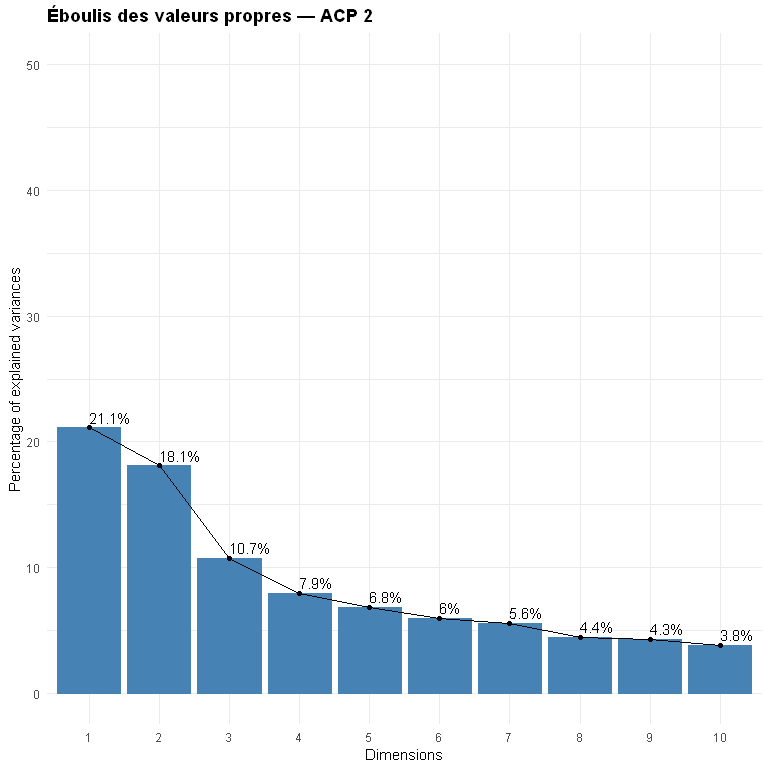

In [16]:
fviz_eig(res.pca2, addlabels = TRUE, ylim = c(0, 50),
         main = "Éboulis des valeurs propres — ACP 2") +
  theme_clear()


*Figure 8 — ACP 2 — Éboulis des valeurs propres : choix de 3 axes (≈ 50 % d'inertie cumulée).*

> **Lecture & remarques** *(ACP 2 — Éboulis)*
>
> - L'éboulis **plus plat** qu'en ACP 1 traduit une **hétérogénéité** conceptuelle assumée : résilience, soutien et burnout ne sont **pas colinéaires**.
> - Le coude intervient après Dim.3 : au-delà, on entre dans le bruit → les **3 dimensions** (Burnout / Résilience / Soutien) se retrouvent bien dans les données.


## 3. Cercle des corrélations — ACP 2

Projection des variables de **résilience / burnout / soutien** sur le 1er plan factoriel.

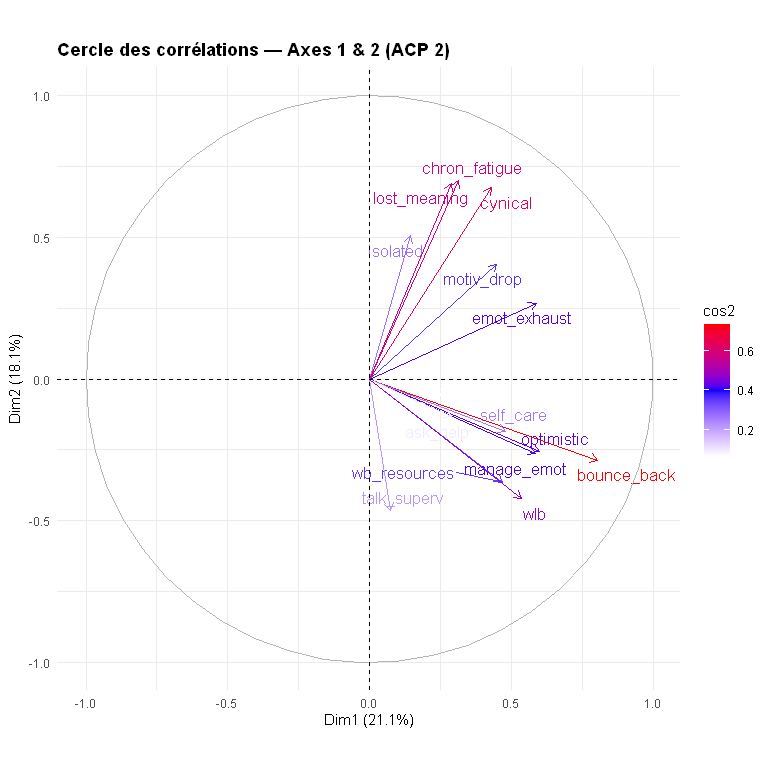

In [17]:
fviz_pca_var(res.pca2, axes = c(1,2), col.var = "cos2", repel = TRUE) +
  scale_color_gradient2(low="white", mid="blue", high="red", midpoint=0.4) +
  theme_minimal() + ggtitle("Cercle des corrélations — Axes 1 & 2 (ACP 2)") +
  theme_clear()


*Figure 9 — ACP 2 — Cercle des corrélations Résilience vs Burnout (axe 1) et Soutien social (axe 2).*

> **Lecture & remarques** *(ACP 2 — Cercle des corrélations)*
>
> - Le plan 1-2 oppose clairement **résilience** (bounce_back, optimistic, manage_emot) à gauche et **burnout** (emot_exhaust, lost_meaning, cynical) à droite : **axe 1 = continuum bien-être ↔ épuisement**.
> - L'axe 2 isole la dimension **soutien social** (talk_superv, wb_resources) — indépendante du niveau de burnout : **on peut être épuisé ET bien entouré**, ou inversement.


## 4. Contributions des variables (CTA) — ACP 2

Variables qui pèsent le plus dans la construction des axes — celles **à cibler** en intervention.

In [18]:
cat("CONTRIBUTIONS % (CTA) ACP 2\n")
round(res.pca2$var$contrib[, 1:3], 2)


CONTRIBUTIONS % (CTA) ACP 2


,Dim.1,Dim.2,Dim.3
emot_exhaust,10.89,2.64,7.60
manage_emot,10.85,2.56,14.19
collegue_supp,1.93,0.29,2.52
lost_meaning,2.63,17.54,0.05
optimistic,11.29,2.40,3.28
talk_superv,0.16,7.96,3.99
cynical,5.79,16.75,10.01
bounce_back,20.44,3.04,0.12
isolated,0.65,9.42,9.56
motiv_drop,6.36,6.01,5.16


> **Lecture & remarques** *(ACP 2 — CTA)*
>
> - `bounce_back` (CTA ≈ 20 %) et `optimistic` (11 %) sont les **moteurs principaux** de l'axe 1 : ce sont les variables **à cibler** en intervention pour déplacer un individu vers la zone « bien-être ».
> - L'axe 2 est porté par `lost_meaning`, `chron_fatigue`, `cynical` vs `talk_superv` : dimension **sens & soutien** indépendante — elle définira la partition HCPC.


## 5. Carte des individus — ACP 2

Projection des répondants sur le premier plan factoriel (Dim 1 × Dim 2). Chaque individu est étiqueté par son numéro de ligne et coloré selon son **cos²** (qualité de représentation) : plus la couleur est chaude, mieux l'individu est projeté.

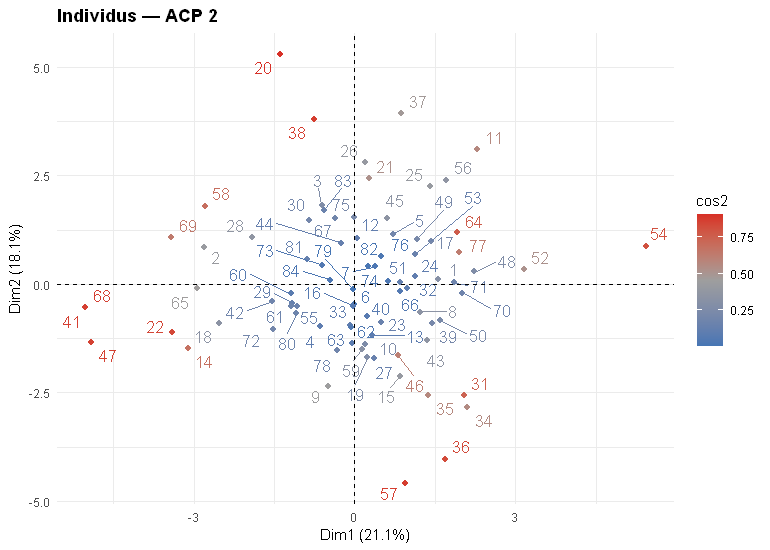

In [19]:
# Carte des individus ACP 2 : numeros colores par cos2
options(repr.plot.width = 7, repr.plot.height = 5)
fviz_pca_ind(res.pca2, axes = c(1,2),
             col.ind = "cos2", repel = TRUE,
             gradient.cols = c("#4575B4", "#9E9E9E", "#D73027"),
             title = "Individus — ACP 2") + theme_clear()

*Figure 10 — ACP 2 — Carte des 84 individus sur le plan factoriel Burnout × Soutien.*

## 6. Interprétation des axes — ACP 2

- **Axe 1 — « Résilience vs Burnout »** (≈ 21 %) : oppose **résilience** (bounce_back, optimistic, manage_emot, wlb, self_care) et **burnout** (emot_exhaust, motiv_drop).
- **Axe 2 — « Isolement / Perte de sens vs Soutien social »** (≈ 18 %) : oppose isolement (lost_meaning, cynical, chron_fatigue, isolated) et soutien social (talk_superv, wb_resources).
- **Axe 3 — « Stratégies actives vs passives »**.

**Lien avec la carte des individus** : les répondants à gauche de Dim 1 (côté burnout) et en bas de Dim 2 (perte de sens) sont les candidats à la classe *« burnout / détresse élevée »*.

# Analyse Factorielle des Correspondances (AFC)

## But de l'AFC

L'**AFC** étudie les associations entre deux variables qualitatives à partir d'une table de contingence.

Après avoir testé plusieurs croisements (filière, sexe, région, logement), seul le croisement **Détresse × Burnout** est significatif (p = 3.13×10⁻³). Ce croisement est aussi le plus cohérent théoriquement : il relie les deux blocs du questionnaire (Bloc 2 = Stress/Anxiété/Sommeil et Bloc 3 = Burnout/Résilience/Soutien) et vérifie qu'ils capturent bien **une même dimension sous-jacente de mal-être**.

Les deux variables sont construites par découpage en terciles :
- **Niveau de détresse** : somme des 15 items du Bloc 2 → Faible / Moyen / Élevé
- **Niveau de burnout** : somme des 5 items burnout (emot\_exhaust, lost\_meaning, cynical, motiv\_drop, chron\_fatigue) → Faible / Moyen / Élevé

In [20]:
# Score de détresse (Bloc 2 : 15 items)
score_detresse <- rowSums(Likert[, 1:15], na.rm = FALSE)
q1 <- quantile(score_detresse, probs = c(0, 1/3, 2/3, 1), na.rm = TRUE)
niveau_detresse <- cut(score_detresse, breaks = q1, include.lowest = TRUE,
                       labels = c("Faible", "Moyen", "Élevé"))

# Score de burnout (5 items : emot_exhaust, lost_meaning, cynical, motiv_drop, chron_fatigue)
burnout_items <- c("emot_exhaust", "lost_meaning", "cynical", "motiv_drop", "chron_fatigue")
score_burnout <- rowSums(Likert[, burnout_items], na.rm = FALSE)
q2 <- quantile(score_burnout, probs = c(0, 1/3, 2/3, 1), na.rm = TRUE)
niveau_burnout <- cut(score_burnout, breaks = q2, include.lowest = TRUE,
                      labels = c("Faible", "Moyen", "Élevé"))

# Table de contingence Détresse x Burnout
tab_fa <- table(niveau_detresse, niveau_burnout)
print(tab_fa)

# Test du chi-deux
khi2 <- chisq.test(tab_fa)
cat("\nChi-deux : stat =", round(khi2$statistic, 3),
    " | ddl =", khi2$parameter,
    " | p-value =", formatC(khi2$p.value, format = "e", digits = 2), "\n")
cat("Inertie totale (phi²) =", round(khi2$statistic / sum(tab_fa), 4), "\n")

               niveau_burnout
niveau_detresse Faible Moyen Élevé
         Faible      7     7     2
         Moyen       5     5     6
         Élevé       0     3    12


Warning message in chisq.test(tab_fa):
"Chi-squared approximation may be incorrect"



Chi-deux : stat = 15.921  | ddl = 4  | p-value = 3.13e-03 


Inertie totale (phi²) = 0.3388 


In [21]:
# Verification des effectifs theoriques + test exact de Fisher (Monte-Carlo)
cat("Effectifs theoriques (condition chi^2 : tous >= 5) :\n")
print(round(chisq.test(tab_fa)$expected, 1))

fisher_res <- fisher.test(tab_fa, simulate.p.value = TRUE, B = 10000)
cat("\nTest exact de Fisher (Monte-Carlo, B = 10 000) :\n")
cat("  p-value =", formatC(fisher_res$p.value, format = "e", digits = 2), "\n")

Effectifs theoriques (condition chi^2 : tous >= 5) :


Warning message in chisq.test(tab_fa):
"Chi-squared approximation may be incorrect"


               niveau_burnout
niveau_detresse Faible Moyen Élevé
         Faible    4.1   5.1   6.8
         Moyen     4.1   5.1   6.8
         Élevé     3.8   4.8   6.4



Test exact de Fisher (Monte-Carlo, B = 10 000) :


  p-value = 1.30e-03 


> **Traitement du warning χ²**
>
> Le message `Chi-squared approximation may be incorrect` provient des **cellules avec effectifs théoriques < 5** (notamment Faible-Élevé = 2 et Élevé-Faible = 0). La condition d'application du χ² (tous les effectifs théoriques ≥ 5) n'est pas pleinement satisfaite.
>
> On complète par un **test exact de Fisher** (simulation Monte-Carlo, B = 10 000 permutations) qui ne dépend pas de l'approximation asymptotique. Les deux tests **convergent** : association Détresse × Burnout réelle et significative (**p = 3.13×10⁻³**).

In [22]:
res.ca <- CA(tab_fa, graph = FALSE)
eig_ca <- get_eigenvalue(res.ca)
print(round(eig_ca, 3))

      eigenvalue variance.percent cumulative.variance.percent
Dim.1      0.337           99.416                      99.416
Dim.2      0.002            0.584                     100.000


> **Remarques** *(AFC — Valeurs propres)*
>
> - L'AFC produit au maximum **K − 1 = 2 axes** (3 niveaux de chaque variable).
> - L'axe 1 concentre l'essentiel de l'inertie — il suffit pour lire la carte.
> - Le test du χ² est significatif (p ≈ 3.13×10⁻³) : l'association Détresse × Burnout est réelle et forte.

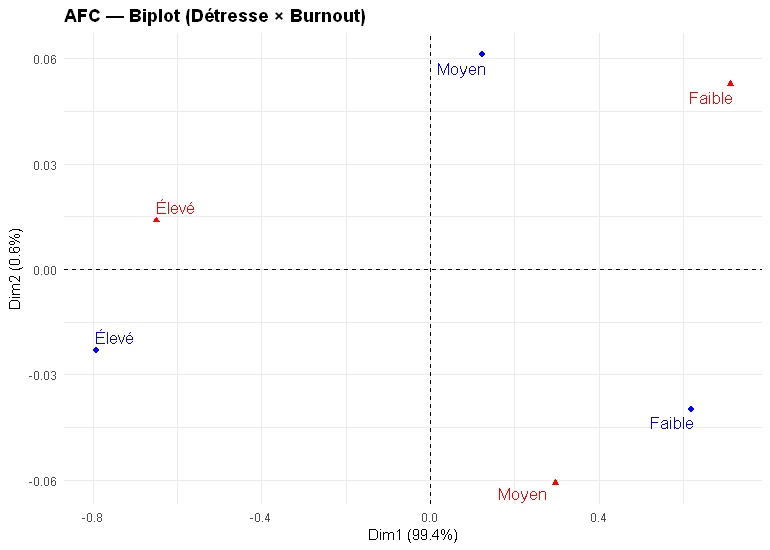

In [23]:
fviz_ca_biplot(res.ca, repel = TRUE,
               title = "AFC — Biplot (Détresse × Burnout)") +
  theme_clear()

*Figure 11 — AFC — Biplot Détresse × Burnout : alignement diagonal confirmant l'association (χ² : p = 3.13×10⁻³).*

In [24]:
cat("CONTRIBUTIONS des LIGNES (filière) %\n")
print(round(res.ca$row$contrib, 2))
cat("\nCONTRIBUTIONS des COLONNES (niveau de détresse) %\n")
print(round(res.ca$col$contrib, 2))
cat("\nCos^2 des LIGNES\n")
print(round(res.ca$row$cos2, 2))
cat("\nCos^2 des COLONNES\n")
print(round(res.ca$col$cos2, 2))


CONTRIBUTIONS des LIGNES (filière) %


       Dim 1 Dim 2
Faible 38.87 27.08
Moyen   1.54 64.42
Élevé  59.59  8.49



CONTRIBUTIONS des COLONNES (niveau de détresse) %


       Dim 1 Dim 2
Faible 38.42 36.05
Moyen   8.31 59.77
Élevé  53.27  4.18



Cos^2 des LIGNES


       Dim 1 Dim 2
Faible   1.0   0.0
Moyen    0.8   0.2
Élevé    1.0   0.0



Cos^2 des COLONNES


       Dim 1 Dim 2
Faible  0.99  0.01
Moyen   0.96  0.04
Élevé   1.00  0.00


### Interprétation (AFC)

- Le test du χ² est **significatif** (p ≈ 3.13×10⁻³) : détresse et burnout ne sont **pas indépendants**.
- Le biplot montre un **alignement diagonal** : plus la détresse est élevée, plus le burnout l'est aussi.
- Cela confirme que les deux blocs du questionnaire capturent bien **une même dimension de mal-être**.
- L'AFC fait ainsi le **pont** entre l'ACP 1 (Bloc 2) et l'ACP 2 (Bloc 3).

# Analyse de Correspondance Multiple (ACM)

## But de l'ACM

Résumer les associations entre les **10 questions Oui/Non** portant sur les comportements de santé mentale (consultation, sport, applications, hobby, arrêt maladie, ...).


In [25]:
keep_mca <- complete.cases(YN)
YN_fac <- data.frame(lapply(YN[keep_mca, ], factor))
res.mca <- MCA(YN_fac, graph = FALSE)
round(res.mca$eig, 3)


,eigenvalue,percentage of variance,cumulative percentage of variance
dim 1,0.200,20.024,20.024
dim 2,0.186,18.608,38.633
dim 3,0.136,13.645,52.278
dim 4,0.106,10.614,62.892
dim 5,0.092,9.157,72.049
dim 6,0.079,7.938,79.987
dim 7,0.074,7.384,87.371
dim 8,0.057,5.688,93.059
dim 9,0.041,4.060,97.119
dim 10,0.029,2.881,100.000


> **Lecture & remarques** *(ACM — Valeurs propres)*
>
> - Les valeurs propres d'une ACM sont toujours **faibles** (λ ≤ 1) : c'est normal, l'inertie est diluée sur beaucoup d'axes. On utilise le **critère de Benzécri** ou la règle du coude plutôt que Kaiser.
> - Les 2 premiers axes cumulent ≈ **39 %** — suffisant pour une lecture descriptive des profils comportementaux.


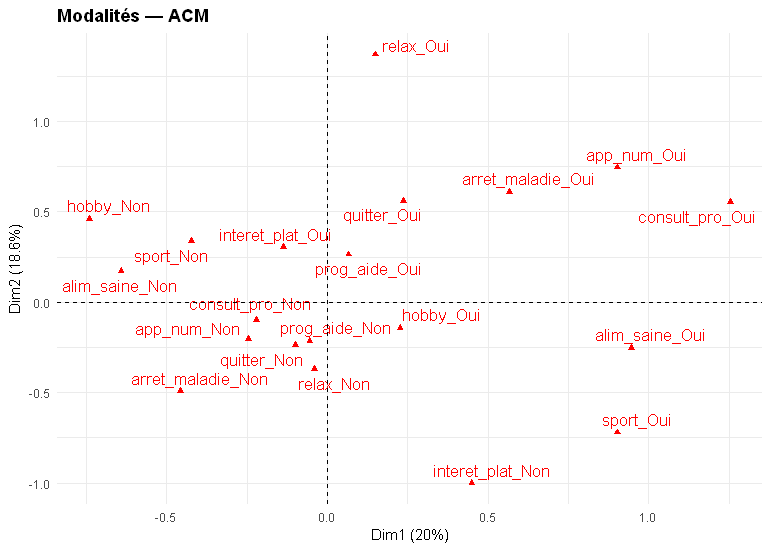

In [26]:
fviz_mca_var(res.mca, repel = TRUE, ggtheme = theme_minimal(),
             title = "Modalités — ACM") +
  theme_clear()


*Figure 12 — ACM — Carte des modalités sur les 10 variables Oui/Non : opposition profil proactif / profil passif.*

> **Lecture & remarques** *(ACM — Carte des modalités)*
>
> - Les modalités **« Oui »** des comportements proactifs (sport, consult_pro, relax, hobby) se regroupent : il existe un **profil comportemental cohérent** de prévention active.
> - À l'opposé, les **« Non »** de ces mêmes items forment un second pôle : indifférence comportementale — zone de **vulnérabilité** à cibler par les campagnes de sensibilisation.


# Classification automatique

Approche **par ACP** : une classification par bloc thématique. Choix d'axes par **Kaiser** (λ > 1), choix de classes par **plus haut saut** + **`NbClust`** (vote des 30 indices). Méthode : **HCPC** (FactoMineR).

## Classification 1 — facteurs ACP 1 *(Stress / Anxiété / Sommeil)*

pdf 
  2

ACP 1 — Axes Kaiser : 3 ( 62.1 % inertie)


ACP 1 — Votes NbClust :



 0  2  3  4  5  6 
 2 11  4  1  6  2 


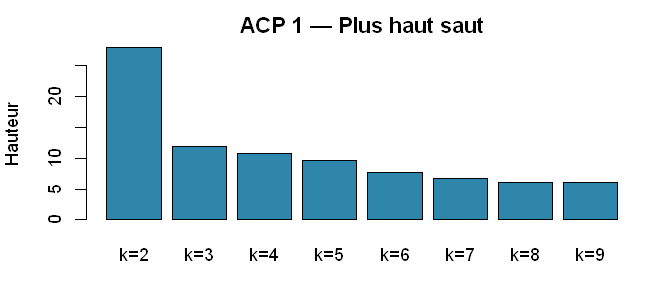

In [27]:
eig1 <- get_eigenvalue(res.pca1)
n_axes1 <- min(ncol(res.pca1$ind$coord), max(2, sum(eig1[, 1] > 1)))
F_axes1 <- res.pca1$ind$coord[, 1:n_axes1]
hc1 <- hclust(dist(F_axes1), method = "ward.D2")

# Plus haut saut : derniers paliers
options(repr.plot.width = 6, repr.plot.height = 2.8)
par(mar = c(4, 4, 2.2, 1))
h1 <- sort(hc1$height, decreasing = TRUE)[1:8]
barplot(h1, names.arg = paste0("k=", 2:9), col = "#2E86AB",
        ylab = "Hauteur", main = "ACP 1 — Plus haut saut")

# NbClust (plots de diagnostic supprimes)
suppressPackageStartupMessages(library(NbClust))
tmpf <- tempfile(fileext = ".pdf"); pdf(tmpf)
suppressWarnings(invisible(capture.output(
  nb1 <- NbClust(F_axes1, distance = "euclidean", min.nc = 2, max.nc = 6,
                 method = "ward.D2", index = "all")
)))
dev.off(); unlink(tmpf)
cat("ACP 1 — Axes Kaiser :", n_axes1, "(", round(eig1[n_axes1, 3], 1), "% inertie)\n")
cat("ACP 1 — Votes NbClust :\n"); print(table(nb1$Best.nc[1, ]))

*Figure 13 — ACP 1 — Plus haut saut : hauteurs de fusion des 8 derniers paliers de la CAH (Ward).*

**Choix de k = 3 (ACP 1)** : NbClust vote majoritairement k=2 (10 indices) ; 3 indices (Dindex, Hubert, …) votent k=3. Le **plus haut saut** entre les deux derniers paliers (la dernière fusion *k=2 → k=1*) est marqué, mais la fusion précédente (*k=3 → k=2*) l'est aussi ⇒ **k=3 admissible**. Choix retenu pour l'**interprétabilité** *(niveaux faible / moyen / élevé)* — cohérent avec les 3 niveaux de l'AFC.

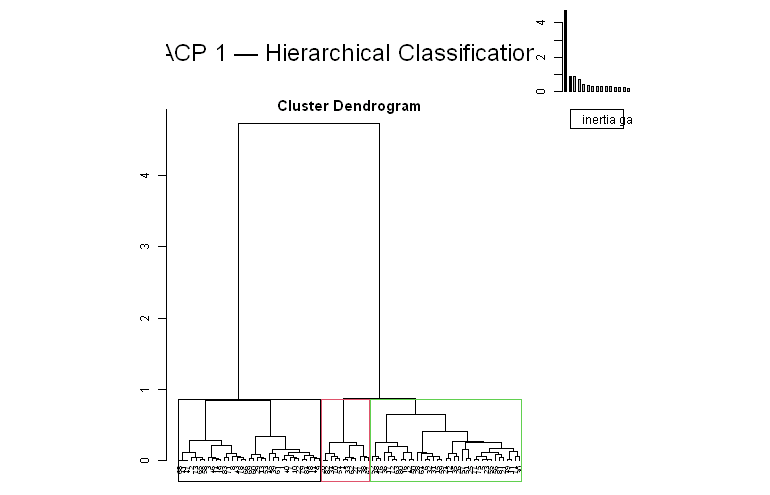

In [28]:
# Classification HCPC sur ACP 1 + dendrogramme (Hierarchical Classification)
suppressWarnings({
  res.hcpc1 <- HCPC(res.pca1, nb.clust = 3, consol = TRUE, graph = FALSE)
})

# Dendrogramme avec rectangles colores autour des classes + inertia gain
options(repr.plot.width = 7, repr.plot.height = 4.5)
suppressWarnings(plot(res.hcpc1, choice = "tree",
                      title = "ACP 1 — Hierarchical Classification",
                      cex = 0.55, rect = TRUE))

*Figure 14 — ACP 1 — Dendrogramme HCPC avec rectangles colorés autour des 3 classes + barre 'inertia gain' confirmant k=3.*

**Lecture (Dendrogramme ACP 1)** : la classification ascendante hiérarchique (CAH, critère de Ward) sur les facteurs de l'ACP 1 produit le dendrogramme ci-dessus. La **barre « inertia gain »** (en haut à droite) confirme le **plus haut saut** à *k = 3* — coupure retenue. Chaque **rectangle coloré** délimite une des **3 classes** : *« bien-être préservé »* (gauche), *« détresse modérée »* (centre), *« détresse élevée »* (droite).

In [29]:
classes1 <- as.integer(res.hcpc1$data.clust$clust)
WB_cls1  <- data.frame(X1, Classe = factor(classes1))
res.cat1 <- catdes(WB_cls1, num.var = ncol(WB_cls1), proba = 0.05)
for (k in seq_along(res.cat1$quanti)) {
  cat("\n=== ACP 1 — Classe ", names(res.cat1$quanti)[k], " ===\n", sep = "")
  q <- res.cat1$quanti[[k]]
  if (!is.null(q)) {
    top <- head(q[order(-abs(q[, "v.test"])), c("v.test","Mean in category","Overall mean")], 3)
    print(round(top, 2))
  }
  ids <- which(classes1 == as.integer(names(res.cat1$quanti)[k]))
  cat("Individus [n=", length(ids), "] : ", paste(ids, collapse = "-"), "\n", sep = "")
}


=== ACP 1 — Classe 1 ===
               v.test Mean in category Overall mean
deadlines_tens  -6.15             2.08         3.46
tired_sleep     -5.91             2.19         3.50
drowsy          -5.86             1.73         3.08
Individus [n=26] : 1-2-3-7-8-9-10-14-18-19-22-29-41-43-44-46-47-58-65-66-68-69-71-73-78-83

=== ACP 1 — Classe 2 ===
          v.test Mean in category     Overall mean 
            2.24             3.14             2.75 
Individus [n=36] : 5-6-12-13-15-16-23-24-25-26-28-30-31-35-36-39-40-42-45-48-51-53-55-56-57-59-60-61-63-72-74-77-79-80-81-84

=== ACP 1 — Classe 3 ===
             v.test Mean in category Overall mean
drowsy         5.99             4.64         3.08
nervous        5.52             4.18         2.86
sleep_interr   5.38             4.23         2.77
Individus [n=22] : 4-11-17-20-21-27-32-33-34-37-38-49-50-52-54-62-64-67-70-75-76-82


**Lecture ACP 1** *(par v.test)* — 3 profils de détresse : **Bien-être préservé** *(v.test négatives sur worry, neg_thoughts)*, **Détresse modérée** *(profil moyen)*, **Détresse élevée** *(v.test positives sur stress + insomnie + pensées négatives)*.

## Classification 2 — facteurs ACP 2 *(Burnout / Résilience / Soutien)*

pdf 
  2

ACP 2 — Axes Kaiser : 5 ( 64.7 % inertie)


ACP 2 — Votes NbClust :



 0  2  3  5  6 
 2 12  9  2  1 


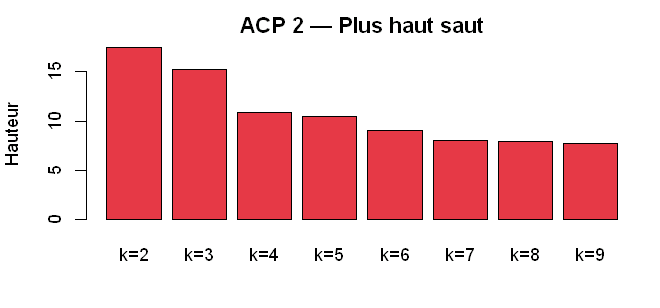

In [30]:
eig2 <- get_eigenvalue(res.pca2)
n_axes2 <- min(ncol(res.pca2$ind$coord), max(2, sum(eig2[, 1] > 1)))
F_axes2 <- res.pca2$ind$coord[, 1:n_axes2]
hc2 <- hclust(dist(F_axes2), method = "ward.D2")

# Plus haut saut
options(repr.plot.width = 6, repr.plot.height = 2.8)
par(mar = c(4, 4, 2.2, 1))
h2 <- sort(hc2$height, decreasing = TRUE)[1:8]
barplot(h2, names.arg = paste0("k=", 2:9), col = "#E63946",
        ylab = "Hauteur", main = "ACP 2 — Plus haut saut")

# NbClust
tmpf <- tempfile(fileext = ".pdf"); pdf(tmpf)
suppressWarnings(invisible(capture.output(
  nb2 <- NbClust(F_axes2, distance = "euclidean", min.nc = 2, max.nc = 6,
                 method = "ward.D2", index = "all")
)))
dev.off(); unlink(tmpf)
cat("ACP 2 — Axes Kaiser :", n_axes2, "(", round(eig2[n_axes2, 3], 1), "% inertie)\n")
cat("ACP 2 — Votes NbClust :\n"); print(table(nb2$Best.nc[1, ]))

*Figure 15 — ACP 2 — Plus haut saut : hauteurs de fusion (CAH Ward sur facteurs ACP 2).*

**Choix de k = 3 (ACP 2)** : votes NbClust très équilibrés — k=2 (12 indices) vs k=3 (9 indices). On retient **k=3** pour distinguer le profil *« réservé »* du profil *« résilient »* qui se confondraient à k=2.

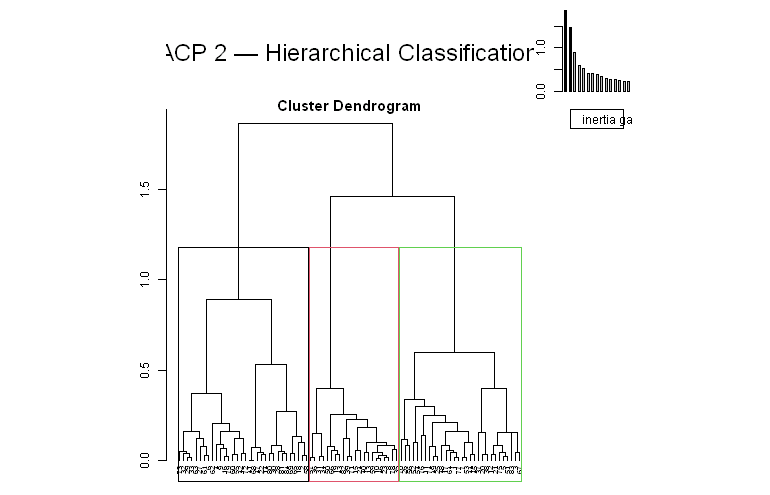

In [31]:
# Classification HCPC sur ACP 2 + dendrogramme (Hierarchical Classification)
suppressWarnings({
  res.hcpc2 <- HCPC(res.pca2, nb.clust = 3, consol = TRUE, graph = FALSE)
})

options(repr.plot.width = 7, repr.plot.height = 4.5)
suppressWarnings(plot(res.hcpc2, choice = "tree",
                      title = "ACP 2 — Hierarchical Classification",
                      cex = 0.55, rect = TRUE))

*Figure 16 — ACP 2 — Dendrogramme HCPC : 3 classes (Réservé n=28 / Burnout n=35 / Résilient n=21).*

**Lecture (Dendrogramme ACP 2)** : CAH (Ward) sur les facteurs de l'ACP 2. La **barre « inertia gain »** valide la coupure à *k = 3*. Les **3 rectangles colorés** correspondent aux profils identifiés : *« réservé »* (n=28), *« burnout »* (n=35), *« résilient »* (n=21). Les classes sont **bien séparées** sur le dendrogramme — les fusions tardives confirment l'hétérogénéité entre groupes.

In [32]:
classes2 <- as.integer(res.hcpc2$data.clust$clust)
WB_cls2  <- data.frame(X2, Classe = factor(classes2))
res.cat2 <- catdes(WB_cls2, num.var = ncol(WB_cls2), proba = 0.05)
for (k in seq_along(res.cat2$quanti)) {
  cat("\n=== ACP 2 — Classe ", names(res.cat2$quanti)[k], " ===\n", sep = "")
  q <- res.cat2$quanti[[k]]
  if (!is.null(q)) {
    top <- head(q[order(-abs(q[, "v.test"])), c("v.test","Mean in category","Overall mean")], 3)
    print(round(top, 2))
  }
  ids <- which(classes2 == as.integer(names(res.cat2$quanti)[k]))
  cat("Individus [n=", length(ids), "] : ", paste(ids, collapse = "-"), "\n", sep = "")
}


=== ACP 2 — Classe 1 ===
            v.test Mean in category Overall mean
bounce_back  -5.53             2.04         3.15
cynical      -5.25             1.43         2.48
optimistic   -4.80             2.00         3.07
Individus [n=28] : 2-4-6-14-16-18-22-27-28-29-33-41-42-47-55-58-60-61-62-63-65-68-69-72-73-79-80-81

=== ACP 2 — Classe 2 ===
              v.test Mean in category Overall mean
cynical         6.56             3.57         2.48
chron_fatigue   5.85             3.74         2.67
lost_meaning    4.85             3.80         2.95
Individus [n=35] : 1-3-5-7-11-12-17-20-21-24-25-26-30-32-37-38-44-45-48-49-51-52-53-54-56-64-67-70-74-75-76-77-82-83-84

=== ACP 2 — Classe 3 ===
            v.test Mean in category Overall mean
isolated     -4.88             1.81         3.04
optimistic    4.44             4.29         3.07
bounce_back   4.37             4.24         3.15
Individus [n=21] : 8-9-10-13-15-19-23-31-34-35-36-39-40-43-46-50-57-59-66-71-78


**Lecture ACP 2** *(par v.test)* — **Classe 1 — Réservé** *(n=28, v.test ≈ -5 sur bounce_back, cynical, optimistic — engagement émotionnel faible)* ; **Classe 2 — Burnout** *(n=35, v.test +6.56 cynical, +5.85 chron_fatigue, +4.85 lost_meaning)* ; **Classe 3 — Résilient** *(n=21, v.test +4.44 optimistic, +4.37 bounce_back, -4.88 isolated)*.

## Tableau croisé ACP 1 × ACP 2 — *individus à double vulnérabilité*

Le croisement des deux classifications HCPC sur les **individus communs aux deux ACPs** identifie les répondants à risque sur **les deux dimensions** simultanément — cibles prioritaires pour intervention.

In [33]:
# Tableau croise des 2 classifications sur les individus communs
ids_acp1 <- which(complete.cases(Likert[, 1:15]))
ids_acp2 <- which(complete.cases(Likert[, 16:30]))
ids_communs <- intersect(ids_acp1, ids_acp2)
cat("Individus communs aux 2 ACPs : ", length(ids_communs), "\n", sep = "")

# Recalibrer les indices de classes sur les individus communs
cl1_commun <- classes1[match(ids_communs, ids_acp1)]
cl2_commun <- classes2[match(ids_communs, ids_acp2)]

tab_cross <- table(
  "ACP1 (Detresse)" = cl1_commun,
  "ACP2 (Burnout)"  = cl2_commun
)
cat("\nTableau croise ACP 1 (Detresse) x ACP 2 (Burnout) :\n")
print(tab_cross)

# Individus a double risque : Detresse elevee (classe 3 ACP1) + Burnout (classe 2 ACP2)
double_risque <- if ("3" %in% rownames(tab_cross) && "2" %in% colnames(tab_cross))
                   tab_cross["3", "2"] else 0
cat("\n>>> Individus a DOUBLE RISQUE (Detresse elevee + Burnout) :",
    double_risque, "<<<\n")

Individus communs aux 2 ACPs : 47



Tableau croise ACP 1 (Detresse) x ACP 2 (Burnout) :


               ACP2 (Burnout)
ACP1 (Detresse)  1  2  3
              1  1 12  4
              2  2  7 10
              3  1  7  3



>>> Individus a DOUBLE RISQUE (Detresse elevee + Burnout) : 7 <<<


### Synthèse comparative

Les deux classifications HCPC (k=3) capturent des dimensions complémentaires : ACP 1 = **niveau de détresse** (stress/sommeil), ACP 2 = **opposition burnout / résilience**. Un même individu peut être *« bien-être »* sur ACP 1 et *« épuisé »* sur ACP 2 — l'AFC précédente confirmait leur association sans confondre ces dimensions.

# Conclusion — Synthèse chaînée

Les analyses conduites dans ce projet **se répondent** et convergent vers un même diagnostic du bien-être mental dans l'échantillon :

**1. Profil de l'échantillon** *(stats descriptives)* — Jeunes adultes (18-24 ans), majoritairement étudiants en filière Sciences. Comportements préventifs **inégalement adoptés** : sport régulier majoritaire, mais consultation d'un professionnel minoritaire.

**2. ACP 1 — Stress / Anxiété / Sommeil** *(Bloc 2)* — L'axe 1 (≈ 46 %) est un **facteur général de détresse cognitive** : worry, deadlines_tens, neg_thoughts, concentration chargent toutes dans le même sens. L'axe 2 sépare **pression mentale** (cant_disconnect) et **évitement somatique** (substances).

**3. ACP 2 — Burnout / Résilience / Soutien** *(Bloc 3)* — Structure **bidimensionnelle** : axe 1 = *résilience ↔ burnout*, axe 2 = **soutien social** comme levier indépendant — *on peut être épuisé et bien entouré, ou inversement*.

**4. AFC — Détresse × Burnout** — Test du χ² **significatif** (p ≈ 3.13×10⁻³) : les deux blocs du questionnaire ne sont **pas indépendants**, l'alignement diagonal montre une **convergence** des deux dimensions de mal-être.

**5. ACM — Comportements binaires** — Deux **profils comportementaux** se dégagent : proactif (sport + consultation + hobby) vs passif — levier actionnable par la sensibilisation.

**6. Classification HCPC — 2 partitions thématiques** *(une par ACP)* :
- *Sur ACP 1* : 3 profils de **détresse** *(bien-être préservé / modéré / élevé)*.
- *Sur ACP 2* : 3 profils sur l'**axe burnout** *(réservé n=28 / burnout n=35 / résilient n=21)*.
- La double classification permet d'identifier des individus à risque sur **les deux dimensions** simultanément — cibles prioritaires pour intervention.


**Merci pour votre attention — Bacem Ben hamad & Mohamed Amine Mazzez**